# 一、实验环境与提交要求

## 1.1 第一个代码框：身份与环境记录

In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244081107
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] ALICE
[学号]       20244081107
[机器指纹] f36dbde0167f7177
[RUN_ID]   20244081107-f36dbde0167f7177


# 二、实验内容与过程

## 实验1：NumPy 数组、数据类型与索引

### 2.1.1 
分别创建整数、浮点数和布尔值 ndarray，输出每个数组的 dtype、shape 和
ndim。解释 NumPy 数组的数据类型与 Python 列表的差别。

In [2]:
int_array = np.array([1, 2, 3])
float_array = np.array([1.0, 2.5, 3.8])
bool_array = np.array([True, False, True])
for name, array in [("整数", int_array), ("浮点数", float_array), ("布尔值", bool_array)]:
    print(f"{name}: {array}, dtype={array.dtype}, shape={array.shape}, ndim={array.ndim}")
print("NumPy 数组的元素采用统一的数据类型，Python 列表可以同时存放不同类型的元素。")

整数: [1 2 3], dtype=int64, shape=(3,), ndim=1
浮点数: [1.  2.5 3.8], dtype=float64, shape=(3,), ndim=1
布尔值: [ True False  True], dtype=bool, shape=(3,), ndim=1
NumPy 数组的元素采用统一的数据类型，Python 列表可以同时存放不同类型的元素。


### 2.1.2 
用 np.arange(12) 创建一维数组，并分别变为形状 (3, 4) 和 (2, 3, 2) 的
数组。展示数组内容，说明改变形状时元素总数必须满足什么条件。

In [3]:
array_1d = np.arange(12)
array_2d = array_1d.reshape(3, 4)
array_3d = array_1d.reshape(2, 3, 2)
print("一维数组：\n", array_1d)
print("形状 (3, 4)：\n", array_2d)
print("形状 (2, 3, 2)：\n", array_3d)
print("改变形状时元素总数不变，新形状各维度的乘积必须等于原数组的元素个数。")

一维数组：
 [ 0  1  2  3  4  5  6  7  8  9 10 11]
形状 (3, 4)：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
形状 (2, 3, 2)：
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
改变形状时元素总数不变，新形状各维度的乘积必须等于原数组的元素个数。


### 2.1.3 
对形状为 (3, 4) 的数组完成以下索引：取第 2 行、取第 1 至第 3 列、取大于 6
的元素，并分别输出结果及其形状。

In [4]:
second_row = array_2d[1]
first_three_columns = array_2d[:, :3]
greater_than_six = array_2d[array_2d > 6]
for name, result in [("第2行", second_row), ("第1至第3列", first_three_columns), ("大于6的元素", greater_than_six)]:
    print(f"{name}：\n{result}\n形状：{result.shape}")

第2行：
[4 5 6 7]
形状：(4,)
第1至第3列：
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
形状：(3, 3)
大于6的元素：
[ 7  8  9 10 11]
形状：(5,)


### 2.1.4 
使用 np.arange(10) 分别选出“小于 2 或大于 7”和“大于 3 且小于 7”的元素。使
用括号配合 |、& 或 np.logical_or()、np.logical_and()。

In [5]:
numbers = np.arange(10)
print("小于2或大于7：", numbers[(numbers < 2) | (numbers > 7)])
print("大于3且小于7：", numbers[(numbers > 3) & (numbers < 7)])

小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]


### 2.1.5 
构造两个形状为 (2, 2) 的数组，对比 *、np.multiply() 与 @、
np.matmul() 的结果，说明逐元素乘法与矩阵乘法的区别。

In [6]:
matrix_a = np.array([[1, 2], [3, 4]])
matrix_b = np.array([[5, 6], [7, 8]])
print("*：\n", matrix_a * matrix_b)
print("np.multiply：\n", np.multiply(matrix_a, matrix_b))
print("@：\n", matrix_a @ matrix_b)
print("np.matmul：\n", np.matmul(matrix_a, matrix_b))
print("* 和 np.multiply 将对应元素相乘；@ 和 np.matmul 对左矩阵的行与右矩阵的列求内积。")

*：
 [[ 5 12]
 [21 32]]
np.multiply：
 [[ 5 12]
 [21 32]]
@：
 [[19 22]
 [43 50]]
np.matmul：
 [[19 22]
 [43 50]]
* 和 np.multiply 将对应元素相乘；@ 和 np.matmul 对左矩阵的行与右矩阵的列求内积。


## 实验2：随机抽样、统计与缺失值

### 2.2.1

使用 np.random 生成 1,000 个均值为 70、标准差为 10 的模拟成绩；用np.clip 将数值限制在 0〜100 范围内。输出样本数、最小值、最大值、均值、标准差和极
差。

In [7]:
scores = np.clip(np.random.normal(70, 10, 1000), 0, 100)
print("样本数：", scores.size)
print("最小值：", scores.min())
print("最大值：", scores.max())
print("均值：", scores.mean())
print("标准差：", scores.std())
print("极差：", np.ptp(scores))

样本数： 1000
最小值： 40.830986375807186
最大值： 99.4283081097048
均值： 69.41682460008
标准差： 9.869382543308362
极差： 58.597321733897616


### 2.2.2 
从 np.arange(1, 11) 中不放回地抽取 5 个整数，比较均匀抽样与按整数大小成
比例加权抽样的写法。

In [8]:
population = np.arange(1, 11)
uniform_sample = np.random.choice(population, size=5, replace=False)
weights = population / population.sum()
weighted_sample = np.random.choice(population, size=5, replace=False, p=weights)
print("均匀抽样：", uniform_sample)
print("比例加权抽样：", weighted_sample)
print("均匀抽样不指定 p；加权抽样通过 p 指定与整数大小成比例的概率。")

均匀抽样： [ 2  3  6  8 10]
比例加权抽样： [ 5  6  8 10  7]
均匀抽样不指定 p；加权抽样通过 p 指定与整数大小成比例的概率。


### 2.2.3 
分别演示随机排列后保留原数组和原地打乱数组，打印操作前后的原数组以说明两
种方式的区别。

In [9]:
original = np.arange(10)
print("随机排列前的原数组：", original)
permuted = np.random.permutation(original)
print("随机排列结果：", permuted)
print("随机排列后的原数组：", original)
print("原地打乱前的原数组：", original)
np.random.shuffle(original)
print("原地打乱后的原数组：", original)

随机排列前的原数组： [0 1 2 3 4 5 6 7 8 9]
随机排列结果： [4 2 7 6 1 9 5 8 0 3]
随机排列后的原数组： [0 1 2 3 4 5 6 7 8 9]
原地打乱前的原数组： [0 1 2 3 4 5 6 7 8 9]
原地打乱后的原数组： [4 6 1 7 2 9 0 3 5 8]


### 2.2.4 
将模拟成绩的第 10、20、30 个值设为 np.nan。比较普通均值和忽略缺失值后的均值，统计缺失值个数，并说明 nan 对普通统计函数的影响。

In [10]:
scores[[9, 19, 29]] = np.nan
print("普通均值：", np.mean(scores))
print("忽略缺失值的均值：", np.nanmean(scores))
print("缺失值个数：", np.isnan(scores).sum())
print("nan 会使普通均值等统计结果变为 nan；nanmean 会忽略缺失值。")

普通均值： nan
忽略缺失值的均值： 69.42603560880447
缺失值个数： 3
nan 会使普通均值等统计结果变为 nan；nanmean 会忽略缺失值。


### 2.2.5 
将含缺失值的模拟成绩及其序号整理成内存中的表格变量，供实验4直接使用；不要写入磁盘。

In [11]:
scores_df = pd.DataFrame({"Number": np.arange(1, scores.size + 1), "Score": scores})
print(scores_df)

     Number      Score
0         1  67.752294
1         2  85.527126
2         3  75.903385
3         4  74.416134
4         5  78.761747
..      ...        ...
995     996  68.695980
996     997  78.861180
997     998  56.297174
998     999  66.155594
999    1000  51.475042

[1000 rows x 2 columns]


## 实验3：SciPy 数值计算与 Matplotlib 可视化

### 2.3.1 
使用 scipy.linalg.solve() 解线性方程组 $3x+y=9$、$x+2y=8$；用 NumPy 代入验证求得的解。

In [12]:
from scipy import linalg, optimize, stats

coefficients = np.array([[3, 1], [1, 2]])
constants = np.array([9, 8])
solution = linalg.solve(coefficients, constants)
print("解 [x, y]：", solution)
print("代入左侧：", coefficients @ solution)
print("是否满足方程组：", np.allclose(coefficients @ solution, constants))

解 [x, y]： [2. 3.]
代入左侧： [9. 8.]
是否满足方程组： True


### 2.3.2 
使用 scipy.optimize.root() 求方程 $x^2-2=0$ 的正根和负根，分别给出初始猜测值。打印求根是否成功以及结果，并检查函数值是否接近 0。

In [13]:
def root_function(x):
    return x**2 - 2

for initial_guess in [1.0, -1.0]:
    root_result = optimize.root(root_function, initial_guess)
    residual = root_function(root_result.x)
    print("初始猜测：", initial_guess)
    print("求根成功：", root_result.success, "根：", root_result.x[0])
    print("函数值：", residual[0], "是否接近0：", np.allclose(residual, 0))

初始猜测： 1.0
求根成功： True 根： 1.4142135623730947
函数值： -8.881784197001252e-16 是否接近0： True
初始猜测： -1.0
求根成功： True 根： -1.4142135623730947
函数值： -8.881784197001252e-16 是否接近0： True


### 2.3.3
使用 scipy.optimize.minimize() 求 $f(x)=x^2+x+2$ 的最小值，报告极小点和函数值，并与解析结果比较。

In [14]:
def objective(x):
    return x[0]**2 + x[0] + 2

minimum_result = optimize.minimize(objective, x0=[0.0])
print("极小点：", minimum_result.x[0])
print("最小值：", minimum_result.fun)
print("解析式 f(x)=(x+0.5)^2+1.75，极小点为-0.5，最小值为1.75。")
print("与解析结果一致：", np.allclose([minimum_result.x[0], minimum_result.fun], [-0.5, 1.75]))

极小点： -0.5000000064345924
最小值： 1.75
解析式 f(x)=(x+0.5)^2+1.75，极小点为-0.5，最小值为1.75。
与解析结果一致： True


### 2.3.4
生成两组独立的模拟样本：各 100 个观测值，第一组来自均值 0、标准差 1 的正态分布，第二组来自均值 1、标准差 1 的正态分布。固定随机种子，使用 scipy.stats.ttest_ind() 进行独立样本 t 检验；报告 t 统计量、p 值及在 0.05 显著性水平下的判断。

In [15]:
np.random.seed(42)
sample_a = np.random.normal(0, 1, 100)
sample_b = np.random.normal(1, 1, 100)
t_statistic, p_value = stats.ttest_ind(sample_a, sample_b)
print("t统计量：", t_statistic)
print("p值：", p_value)
if p_value < 0.05:
    print("在0.05显著性水平下，拒绝两组总体均值相等的原假设。")
else:
    print("在0.05显著性水平下，不能拒绝两组总体均值相等的原假设。")

t统计量： -8.55145994324873
p值： 3.292961428703696e-15
在0.05显著性水平下，拒绝两组总体均值相等的原假设。


### 2.3.5
用 Matplotlib 为实验2的有效成绩画直方图，并另画箱线图；为函数 $y=x$、$y=x^2$、$y=x^3$ 在 $0\leq x\leq5$ 上画同一坐标系的折线图。每张图包含标题、坐标轴标签，折线图包含图例。直接在 Notebook 中显示图像，不保存为文件。

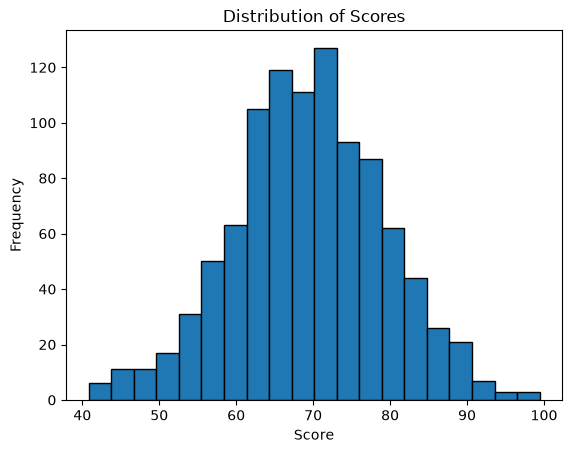

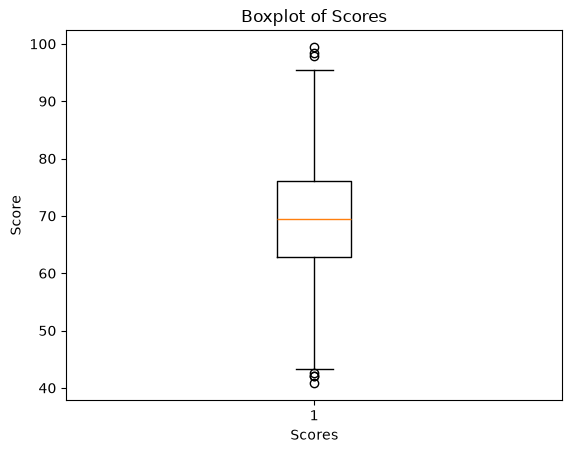

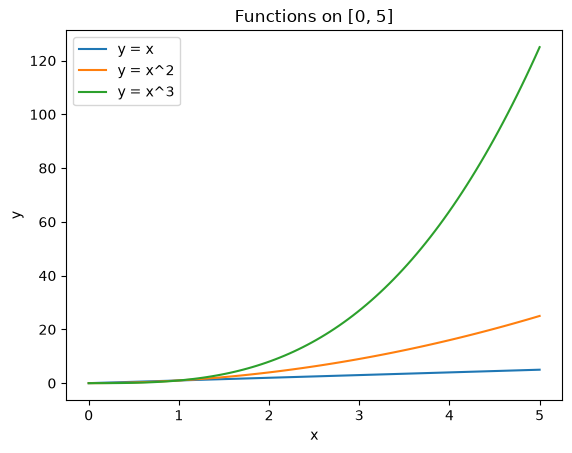

In [16]:
import matplotlib.pyplot as plt

valid_scores = scores[~np.isnan(scores)]
plt.figure()
plt.hist(valid_scores, bins=20, edgecolor="black")
plt.title("Distribution of Scores")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()

plt.figure()
plt.boxplot(valid_scores)
plt.title("Boxplot of Scores")
plt.xlabel("Scores")
plt.ylabel("Score")
plt.show()

x = np.linspace(0, 5, 100)
plt.figure()
plt.plot(x, x, label="y = x")
plt.plot(x, x**2, label="y = x^2")
plt.plot(x, x**3, label="y = x^3")
plt.title("Functions on [0, 5]")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

### 2.4.1
使用以下模拟数据创建 DataFrame，行索引为姓名；计算 Total（三科总分）和 Average（三科平均分）两列。输出行索引、列名、前 3 行和基本统计信息。

In [17]:
records = {
"Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
"Group": ["A", "A", "B", "B", "A", "B"],
"Math": [88, 72, 91, 65, 79, 84],
"English": [90, 68, 85, 73, 92, 77],
"Python": [95, 80, 89, 70, 86, 82],
}

In [18]:
print("实验2的成绩表：")
print(scores_df)
subjects = ["Math", "English", "Python"]
students_df = pd.DataFrame(records).set_index("Name")
students_df["Total"] = students_df[subjects].sum(axis=1)
students_df["Average"] = students_df[subjects].mean(axis=1)
print("行索引：", students_df.index)
print("列名：", students_df.columns)
print("前3行：\n", students_df.head(3))
print("基本统计信息：\n", students_df.describe())

实验2的成绩表：
     Number      Score
0         1  67.752294
1         2  85.527126
2         3  75.903385
3         4  74.416134
4         5  78.761747
..      ...        ...
995     996  68.695980
996     997  78.861180
997     998  56.297174
998     999  66.155594
999    1000  51.475042

[1000 rows x 2 columns]
行索引： Index(['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank'], dtype='str', name='Name')
列名： Index(['Group', 'Math', 'English', 'Python', 'Total', 'Average'], dtype='str')
前3行：
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计信息：
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130  

### 2.4.2
分别用 loc 和 iloc 读取 Carol 的记录，并筛选平均分不低于 80 的学生。

In [19]:
print("loc读取Carol：\n", students_df.loc["Carol"])
print("iloc读取Carol：\n", students_df.iloc[2])
print("平均分不低于80的学生：\n", students_df[students_df["Average"] >= 80])

loc读取Carol：
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc读取Carol：
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分不低于80的学生：
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


### 2.4.3
分别用 mean(axis=0) 和 mean(axis=1) 计算三科成绩的列均值和每名学生的行均值。

In [20]:
print("三科列均值：\n", students_df[subjects].mean(axis=0))
print("每名学生的行均值：\n", students_df[subjects].mean(axis=1))

三科列均值：
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
每名学生的行均值：
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


### 2.4.4
使用 apply() 计算每名学生的三科最高分，使用 agg() 一次得到每科的最小值、均值和最大值。任选一列使用 rank() 给学生排名。

In [21]:
print("每名学生的最高分：\n", students_df[subjects].apply(max, axis=1))
print("各科最小值、均值和最大值：\n", students_df[subjects].agg(["min", "mean", "max"]))
print("Python成绩排名（高分在前）：\n", students_df["Python"].rank(ascending=False))

每名学生的最高分：
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
dtype: int64
各科最小值、均值和最大值：
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
Python成绩排名（高分在前）：
 Name
Alice    1.0
Bob      5.0
Carol    2.0
David    6.0
Eva      3.0
Frank    4.0
Name: Python, dtype: float64


### 2.4.5
按 Group 分组，统计每组人数和三科平均分。再用 transform('mean') 为每行增加其所在组的 Python 平均分。

In [22]:
grouped = students_df.groupby("Group")
print("每组人数：\n", grouped.size())
print("每组三科平均分：\n", grouped[subjects].mean())
students_df["Group_Python_Mean"] = grouped["Python"].transform("mean")
print("各学生及所在组的Python平均分：\n", students_df)

每组人数：
 Group
A    3
B    3
dtype: int64
每组三科平均分：
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333
各学生及所在组的Python平均分：
       Group  Math  English  Python  Total    Average  Group_Python_Mean
Name                                                                   
Alice     A    88       90      95    273  91.000000          87.000000
Bob       A    72       68      80    220  73.333333          87.000000
Carol     B    91       85      89    265  88.333333          80.333333
David     B    65       73      70    208  69.333333          80.333333
Eva       A    79       92      86    257  85.666667          87.000000
Frank     B    84       77      82    243  81.000000          80.333333


### 2.4.6
用 filter() 保留 Python 平均分不低于 80 的组；输出保留的组和学生。

In [23]:
filtered_students = students_df.groupby("Group").filter(lambda group: group["Python"].mean() >= 80)
print("保留的组：", filtered_students["Group"].unique())
print("保留的学生：\n", filtered_students)

保留的组： <StringArray>
['A', 'B']
Length: 2, dtype: str
保留的学生：
       Group  Math  English  Python  Total    Average  Group_Python_Mean
Name                                                                   
Alice     A    88       90      95    273  91.000000          87.000000
Bob       A    72       68      80    220  73.333333          87.000000
Carol     B    91       85      89    265  88.333333          80.333333
David     B    65       73      70    208  69.333333          80.333333
Eva       A    79       92      86    257  85.666667          87.000000
Frank     B    84       77      82    243  81.000000          80.333333


### 2.4.7
计算三科成绩之间的协方差矩阵和皮尔森相关系数矩阵；选择其中一对科目，解释协方差符号与相关系数大小的含义。

In [24]:
covariance = students_df[subjects].cov()
correlation = students_df[subjects].corr(method="pearson")
print("协方差矩阵：\n", covariance)
print("皮尔森相关系数矩阵：\n", correlation)
print("Math与Python的协方差：", covariance.loc["Math", "Python"])
print("Math与Python的相关系数：", correlation.loc["Math", "Python"])
print("协方差为正，说明这两科成绩总体同向变化；相关系数接近1，说明正线性相关较强。")

协方差矩阵：
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
皮尔森相关系数矩阵：
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
Math与Python的协方差： 74.93333333333332
Math与Python的相关系数： 0.8847760993538873
协方差为正，说明这两科成绩总体同向变化；相关系数接近1，说明正线性相关较强。
